# 7.2 Transfer Learning
After learning how to combine outputs of multiple different models for the same task, we are now learning how to exploit knowledge from a pretrained model to solve a related but different task, i.e., transfer learning. Specifically, **we apply transfer learning to classify the 10 objects of the CIFAR-10 dataset: airplanes, automobiles, birds, cats, deers, dogs, frogs, horses, ships, and trucks.**

As we will train various CNN architectures, including a pretrained ResNet50 model from Keras,  This allows faster convergence and improved performance with fewer training resources.

This notebook discusses transfer learning using TensorFlow/Keras, the following computations can be expensive. Therefore, we recommend running this notebook on [Google Colab](https://colab.research.google.com). You can upload it to your own Google Drive and open it with Colab. If you don't want to perform the training yourself, you can also directly load the trained models from the folder `trained_models`.


In [1]:
# %pip install tensorflow keras

In [2]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import json
import keras

We start by defining three helper functions:
-  ``_process_history`` converts a training history to a DataFrame and plots training/validation loss and accuracy over epochs
- `_save_trained_model` ensures the `trained_models` directory exists, and then saves the training history as JSON and the Keras model to a .keras file using the provided model_name
- `load_trained_model` loads the Keras model (if it exists) and returns the training history

In [3]:
def _process_history(history):
    result_frame = pd.DataFrame(history)
    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

    ax[0].plot(
        result_frame[["loss", "val_loss"]],
        label=["Train Loss", "Validation Loss"],
        linewidth=2,
        marker="o",
        markersize=3,
    )

    ax[0].set_ylabel("Loss")
    ax[0].legend(loc="upper left")

    ax[1].plot(
        result_frame[["accuracy", "val_accuracy"]],
        label=["Train Accuracy", "Validation Accuracy"],
        linewidth=2,
        marker="o",
        markersize=3,
    )
    ax[1].set_ylabel("Accuracy")
    ax[1].set_xlabel("Epoch")
    ax[1].legend(loc="upper left")

    plt.subplots_adjust(hspace=0.05)

    plt.show()

def _save_trained_model(model,history, model_name):
    # check if directory exists
    if not os.path.exists(os.path.join(os.getcwd(),"trained_models")):
        os.makedirs(os.path.join(os.getcwd(),"trained_models"))
    with open(os.path.join(os.getcwd(),"trained_models", f"{model_name}_history.json"), 'w') as fp:
        json.dump(history.history, fp)
        
    model.save(os.path.join(os.getcwd(),"trained_models", f"{model_name}.keras"))
    

def _load_trained_model(model_name):
    with open(os.path.join(os.getcwd(),"trained_models", f"{model_name}_history.json"), 'r') as fp:
        history = json.load(fp)
    
    if not os.path.exists(os.path.join(os.getcwd(),"trained_models", f"{model_name}.keras")):
        model = None
    else:
        model = keras.models.load_model(os.path.join(os.getcwd(),"trained_models", f"{model_name}.keras"))
    
    return history, model 

## Data Loading and Preprocessing

We load the CIFAR-10 dataset using TensorFlow/Keras. As preprocessing, we normalize the images to have pixel values between 0 and 1 and convert the labels to categorical encoding.

If you receive this error `URL fetch failure on https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz: None -- [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1006)`, try the following:
- Mac: Move to Applications/Python 3.12 and run `Install Certficates.command`. Restart the kernel and try again.
- Windows: Run this cell `%pip install --upgrade certifi`. Restart the kernel and try again.
- Last resort: Manually download the data from https://www.cs.toronto.edu/~kriz/cifar.html and load it into the notebook.


In [6]:
from keras.datasets import cifar10
from keras.layers import BatchNormalization, Conv2D, Dense, Dropout, Flatten, MaxPool2D, RandomFlip, RandomRotation, RandomTranslation
from keras import Input, Sequential
from keras.utils import to_categorical

# ---- YOUR CODE GOES HERE (START) ---
# load train and test data
(x_train, y_train), (x_test, y_test)=cifar10.load_data()
# normalize pixel values to be between 0 and 1
x_train=x_train/255
x_test=x_test/255
# convert labels to categorical encoding
y_train_cat=to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)
# --- YOUR CODE GOES HERE (END) ---

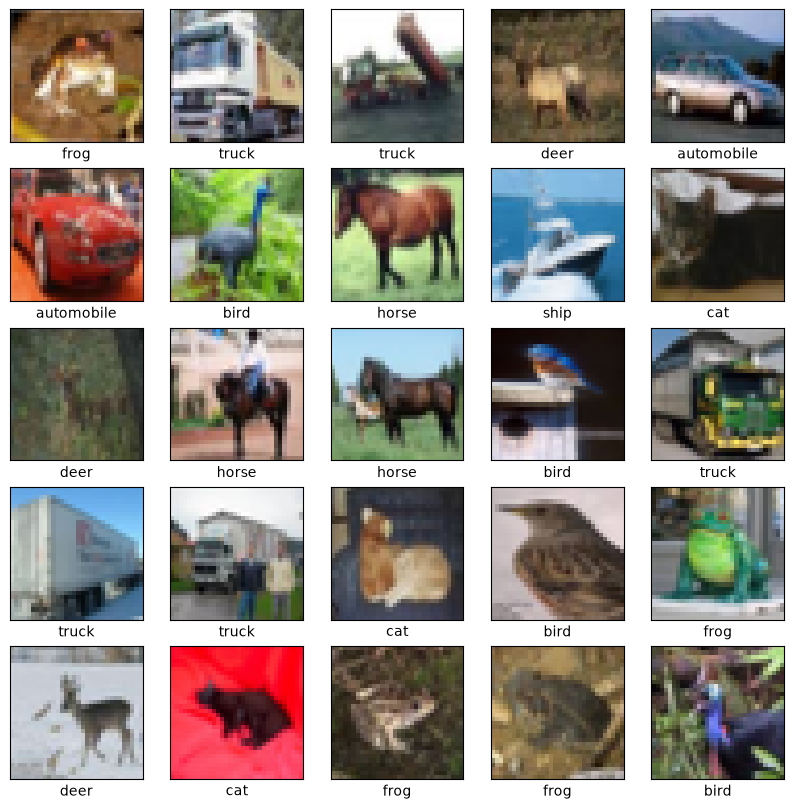

In [7]:
import matplotlib.pyplot as plt
# define class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
# plot first 25 images from training set with labels
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

## Base Model

### **TASK: Base Model Training**
We begin with a simple CNN trained directly on the CIFAR-10 dataset which serves as a baseline to understand model behavior without any prior knowledge.

Create a simple CNN model from scratch and train it on the Cifar 10 dataset. Use the keras Sequential API to build the model with several convolutional, pooling, and dense layers. Compile the model with an appropriate optimizer, loss function, and metrics. Train the model for a specified number of epochs and batch size, and evaluate its performance on the test set. Also, save the training history for later analysis. The architecture should have the following layers:
- Conv2D with 32 filters, kernel size (3,3), activation 'relu', input shape (32, 32, 3)
- MaxPooling2D with pool size (2,2)
- Conv2D with 32 filters, kernel size (3,3), activation 'relu'
- MaxPooling2D with pool size (2,2)
- Flatten
- Dense with 256 units, activation 'relu'
- Dense with 10 units, activation 'softmax'

In [9]:
# define batch size and epochs
BATCH_SIZE = 256
EPOCHS = 100

# define base architecture
base_model = Sequential()
base_model.add(Input(shape=(32, 32, 3)))

# ---- YOUR CODE GOES HERE (START) ---

# layer 1: convolutional layer
base_model.add(Conv2D(32, (4, 4), activation="relu"))

# layer 2: max pooling layer
base_model.add(MaxPool2D(pool_size=(2, 2)))

# layer 3: convolutional layer
base_model.add(Conv2D(64, (3, 3), activation="relu"))

# layer 4: max pooling layer
base_model.add(MaxPool2D(pool_size=(2, 2)))

# layer 5: flatten layer
base_model.add(Flatten())

# layers 6-7: fully connected layers
base_model.add(Dense(256, activation="relu"))
base_model.add(Dense(10, activation="softmax"))

# configure the learning process
base_model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# train the model
base_model_history = base_model.fit(
    x_train,
    y_train_cat,
    epochs=EPOCHS,
    validation_data=(x_test, y_test_cat),
    batch_size=BATCH_SIZE,
    verbose=1
)

# --- YOUR CODE GOES HERE (END) ---

# process and plot training history
_save_trained_model(base_model, base_model_history, "base_model")

Epoch 1/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.4314 - loss: 1.5917 - val_accuracy: 0.5097 - val_loss: 1.3483
Epoch 2/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.5657 - loss: 1.2364 - val_accuracy: 0.5721 - val_loss: 1.2215
Epoch 3/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6145 - loss: 1.1062 - val_accuracy: 0.6234 - val_loss: 1.0729
Epoch 4/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6510 - loss: 0.9990 - val_accuracy: 0.6546 - val_loss: 1.0015
Epoch 5/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6777 - loss: 0.9294 - val_accuracy: 0.6704 - val_loss: 0.9484
Epoch 6/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7016 - loss: 0.8643 - val_accuracy: 0.6829 - val_loss: 0.9234
Epoch 7/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7204 - loss: 0.8104 - val_accuracy: 0.6802 - val_loss: 0.9301
Epoch 8/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7383 - loss: 0.7613 - 

### **TASK: Training Curve**
Plot the training curve using the helper function from above and interpret the curve: Was the training successful? Did it stop at the right time?

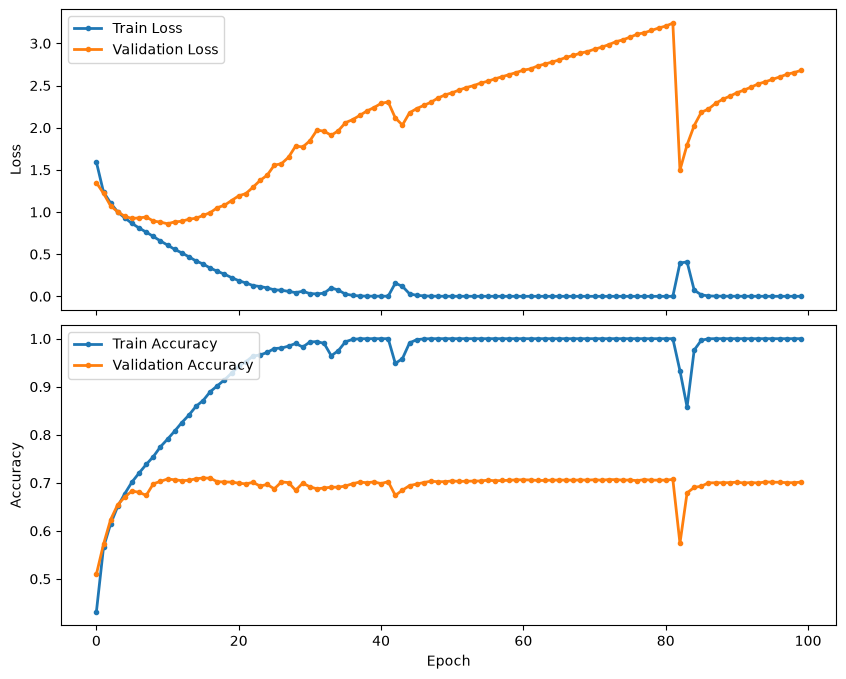

In [10]:
# --- YOUR CODE GOES HERE (START) ---
# load trained model and history
base_model_history, base_model = _load_trained_model("base_model")
# plot training curve
_process_history(base_model_history)
# --- YOUR CODE GOES HERE (END) ---

The training curves show classic **overfitting**. This means the model has learned the training data extremely well but failed to generalize:

- Train loss continually decreases to near zero, while validation loss starts increasing after about 15–20 epochs.  
- Train accuracy reaches nearly 100%, but validation accuracy plateaus around 70% and even degrades slightly near the end.  

Also, the training did not stop at the right time. It should have been stopped earlier (around the point where validation loss was lowest). Using **early stopping** or stronger regularization (dropout, data augmentation, etc.) would likely improve generalization.

## Advanced Model

### TASK: Advanced Model Training
In this task, you will create and train a more advanced model including batch normalization, dropout layers, image augmentation and more convolutional layers. 
- Each Conv2D-Layer should now use the kernel_initializer he_uniform and should be followed by a BatchNormalization layer. 
- After each MaxPooling2D layer, add a Dropout layer with an increasing drop rate of first 0.2, second 0.3 and 0.4. 
- Also have a 0.5 Dropout before the final Dense layers.
- Train the model for a specified number of epochs and batch size, and evaluate its performance on the test set. Also, save the training history for later analysis. The architecture should have the following layers:

In [ ]:
BATCH_SIZE = 256
EPOCHS = 100

# data augmentation pipeline
data_augmentation = Sequential([
    RandomTranslation(height_factor=0.1, width_factor=0.1),
    RandomFlip("horizontal"),
    RandomRotation(0.1),
])

# define base architecture
advanced_model = Sequential()

# ---- YOUR CODE GOES HERE (START) ---
advanced_model.add(Input(shape=(32, 32, 3)))

# data augmentation as first part of the model
advanced_model.add(data_augmentation)
# layer 1: convolutional layer with batch normalization
advanced_model.add(Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"))
advanced_model.add(BatchNormalization())

# layer 2: convolutional layer with batch normalization
advanced_model.add(Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"))
advanced_model.add(BatchNormalization())

# layer 3: max pooling layer with dropout
advanced_model.add(MaxPool2D((2, 2)))
advanced_model.add(Dropout(0.2))

# layer 4: convolutional layer with batch normalization
advanced_model.add(Conv2D(64, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"))
advanced_model.add(BatchNormalization())

# layer 5: convolutional layer with batch normalization
advanced_model.add(Conv2D(64, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"))
advanced_model.add(BatchNormalization())

# layer 6: max pooling layer with dropout
advanced_model.add(MaxPool2D((2, 2)))
advanced_model.add(Dropout(0.3))

# layer 7: convolutional layer with batch normalization
advanced_model.add(Conv2D(128, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"))
advanced_model.add(BatchNormalization())

# layer 8: convolutional layer with batch normalization
advanced_model.add(Conv2D(128, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"))
advanced_model.add(BatchNormalization())

# layer 9: max pooling layer with dropout
advanced_model.add(MaxPool2D((2, 2)))
advanced_model.add(Dropout(0.4))

# layers 10-12: fully connected layers with batch normalization and dropout
advanced_model.add(Flatten())
advanced_model.add(Dense(128, activation="relu", kernel_initializer="he_uniform"))
advanced_model.add(BatchNormalization())
advanced_model.add(Dropout(0.5))
advanced_model.add(Dense(10, activation="softmax"))

# configure the learning process
advanced_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

# train the model
advanced_model_history = advanced_model.fit(
    x_train,
    y_train_cat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test, y_test_cat),
)
# --- YOUR CODE GOES HERE (END) ---

# save trained model and history
_save_trained_model(advanced_model, advanced_model_history, "advanced_model")

### **TASK: Training Curve**
Plot the training curve using the helper function from above and interpret the curve: Was the training successful? Did it stop at the right time?

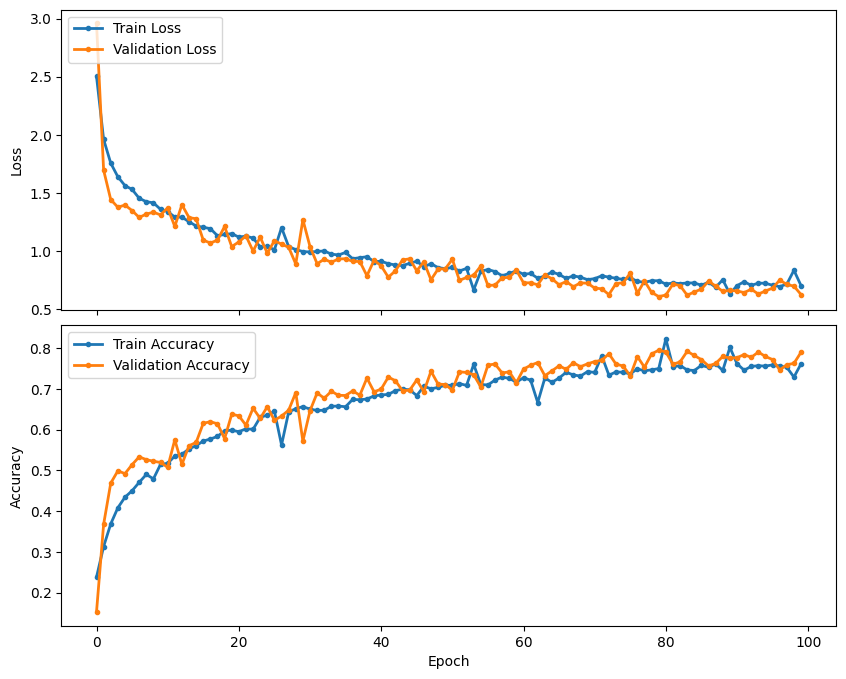

In [ ]:
# load trained model and history
advanced_model_history, advanced_model = _load_trained_model("advanced_model")
# plot training curve
_process_history(advanced_model_history)

This time, the model seems to be learning effectively: losses decrease and accuracies increase steadily until they plateau after 60–70 epochs. 
Thus, we can assume that there is no significant overfitting or underfitting. The model might be near its optimal capacity, as training no longer yields large improvements after 

## Transfer Learning Model

### **TASK: Transfer Learning with Pretrained ResNet50**
Finally, we apply transfer learning by leveraging the pretrained ResNet50 model. We adapt it to CIFAR-10 by resizing inputs, adding global pooling, and customizing the output layer. This shows how pretrained models can quickly achieve high accuracy.

Steps: 
- Load the ResNet50 model without the top classification layer, using weights pretrained on ImageNet. 
- Instanciate a new Sequential model
- To match the input shape to the Cifar 10 images (32, 32, 3) add an UpSampling2D layer
- Add the ResNet50 base model as the first layer
- Add a GlobalAveragePooling2D layer 
- Add a Dense layer with 10 units and softmax activation for Cifar 10 classification
- Train using the previously defined ImageDataGenerator for data augmentation.


In [ ]:
import keras
from keras import layers
from keras.applications import ResNet50

# define batch size and epochs
BATCH_SIZE = 64
EPOCHS = 20

# ---- YOUR CODE GOES HERE (START) ---

# load pretrained ResNet50 without classification head
res_net_base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# freeze pretrained layers
res_net_base_model.trainable = False

# define data augmentation pipeline
data_augmentation = keras.Sequential([
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(20 / 360)
])

# define model input
inputs = keras.Input(shape=(32, 32, 3))

# apply data augmentation
x = data_augmentation(inputs)

# resize CIFAR-10 images to ResNet50 input size
x = layers.Resizing(224, 224)(x)

# ResNet50 preprocessing:
# restore pixel range [0, 255]
x = layers.Rescaling(255.0)(x)

# convert RGB to BGR and subtract ImageNet means
x = keras.ops.flip(x, axis=-1)
x = x - keras.ops.convert_to_tensor([103.939, 116.779, 123.68])

# apply pretrained ResNet50 model
x = res_net_base_model(x, training=False)

# classification head
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation="softmax")(x)

# create transfer learning model
transfer_model = keras.Model(inputs, outputs)

# configure learning process
transfer_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

# train model with augmented data
transfer_model_history = transfer_model.fit(
    x_train,
    y_train_cat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test, y_test_cat)
)

# --- YOUR CODE GOES HERE (END) ---

# save trained model and history
_save_trained_model(transfer_model, transfer_model_history, "transfer_model")

### **TASK: Training Curve**
Plot the training curve using the helper function from above and interpret the curve: Was the training successful? Did it stop at the right time?

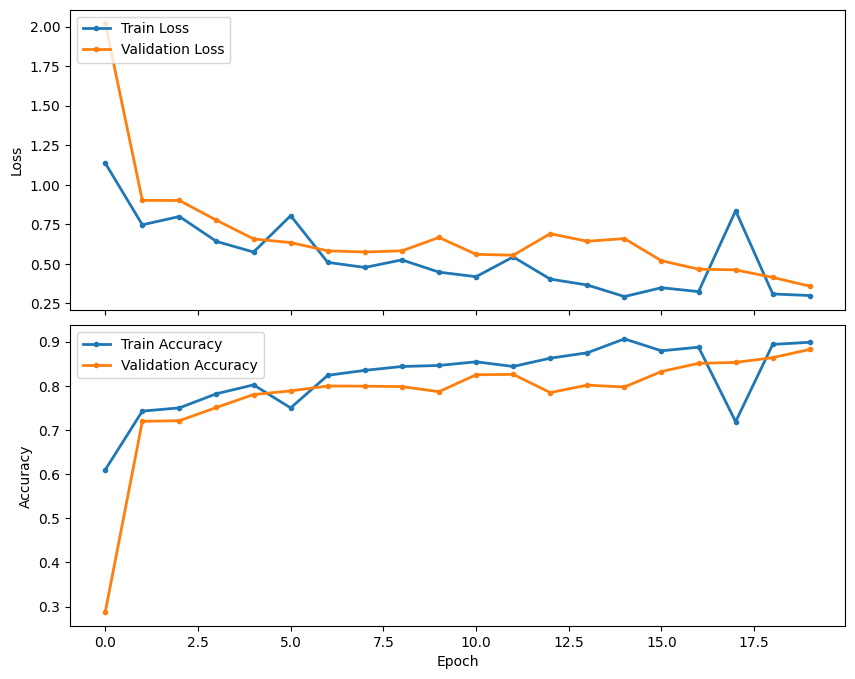

In [ ]:
# load trained model and history
transfer_model_history, transfer_model = _load_trained_model("transfer_model")
# plot training curve
_process_history(transfer_model_history)

Again, the model seems to be learning effectively and converges even more quickly, reaching its plateau in fewer than 10 epochs. Notably, the plateau for the validation accuracy is higher than before, which shows the superiority of leveraging the ResNet50 model as foundation model for transfer learning.

## Performance Comparison

### **TASK: Performance Comparison**
Finally, we can compare the three models (base, advanced, and transfer learning) to analyze how complexity and prior knowledge affect training dynamics and performance. Plot the training and validation accuracy and loss curves for each model using Matplotlib. Analyze the results and discuss the differences in performance.

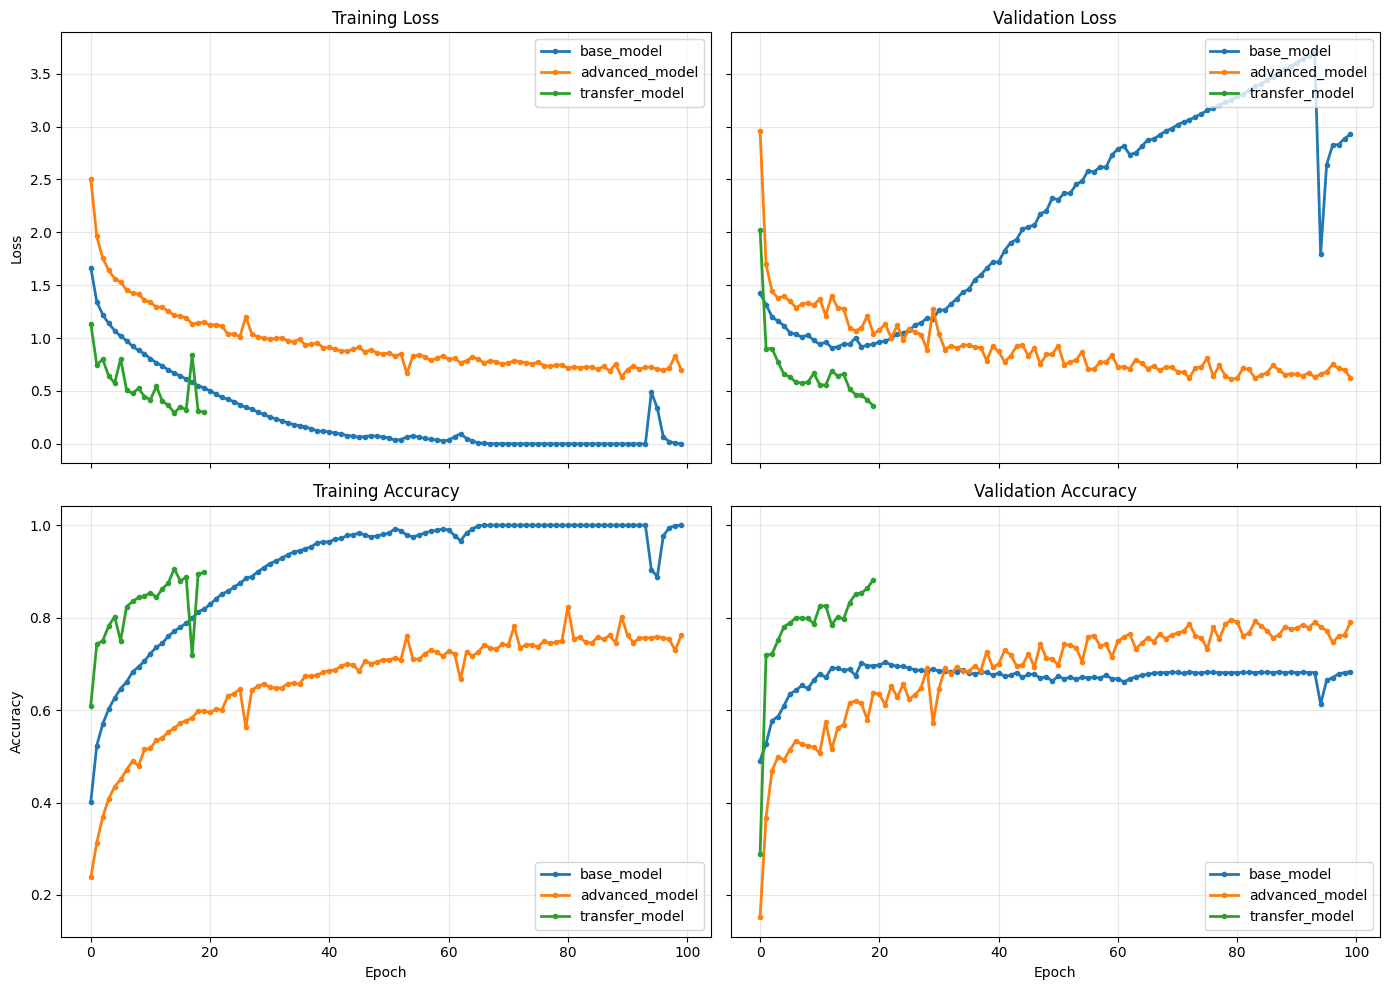

In [14]:
def _compare_models(model_histories):
    """
    Compare multiple model training histories.
    
    Parameters:
    -----------
    model_histories : dict
        Dictionary with model names as keys and history dicts as values.
        Example: {
            'base_model': {'loss': [...], 'val_loss': [...], 'accuracy': [...], 'val_accuracy': [...]},
            'advanced_model': {...}
        }
    """
    # ---- YOUR CODE GOES HERE (START) ---

    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey='row')
    
    # Define colors for different models (cycle through if more models than colors)
    colors = plt.cm.tab10.colors
    
    # Plot Train Loss
    for idx, (model_name, history) in enumerate(model_histories.items()):
        result_frame = pd.DataFrame(history)
        color = colors[idx % len(colors)]
        axes[0, 0].plot(
            result_frame["loss"],
            label=model_name,
            linewidth=2,
            marker="o",
            markersize=3,
            color=color
        )
    axes[0, 0].set_ylabel("Loss")
    axes[0, 0].set_title("Training Loss")
    axes[0, 0].legend(loc="upper right")
    axes[0, 0].grid(True, alpha=0.3)
    
    # Plot Validation Loss
    for idx, (model_name, history) in enumerate(model_histories.items()):
        result_frame = pd.DataFrame(history)
        color = colors[idx % len(colors)]
        axes[0, 1].plot(
            result_frame["val_loss"],
            label=model_name,
            linewidth=2,
            marker="o",
            markersize=3,
            color=color
        )
    axes[0, 1].set_title("Validation Loss")
    axes[0, 1].legend(loc="upper right")
    axes[0, 1].grid(True, alpha=0.3)
    
    # Plot Train Accuracy
    for idx, (model_name, history) in enumerate(model_histories.items()):
        result_frame = pd.DataFrame(history)
        color = colors[idx % len(colors)]
        axes[1, 0].plot(
            result_frame["accuracy"],
            label=model_name,
            linewidth=2,
            marker="o",
            markersize=3,
            color=color
        )
    axes[1, 0].set_ylabel("Accuracy")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_title("Training Accuracy")
    axes[1, 0].legend(loc="lower right")
    axes[1, 0].grid(True, alpha=0.3)
    
    # Plot Validation Accuracy
    for idx, (model_name, history) in enumerate(model_histories.items()):
        result_frame = pd.DataFrame(history)
        color = colors[idx % len(colors)]
        axes[1, 1].plot(
            result_frame["val_accuracy"],
            label=model_name,
            linewidth=2,
            marker="o",
            markersize=3,
            color=color
        )
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_title("Validation Accuracy")
    axes[1, 1].legend(loc="lower right")
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # --- YOUR CODE GOES HERE (END) ---
    

model_histories = {
    'base_model': base_model_history,
    'advanced_model': advanced_model_history,
    'transfer_model': transfer_model_history
}

_compare_models(model_histories)